# Myanmar Food Price Forecasting — Data Exploration

## Notebook purpose

This notebook explores the WFP Myanmar food-price dataset and identifies **candidate time series** for a monthly forecasting project.

The goal at this stage is **not** to train a model. It is to understand the data and select reliable commodity–market series.

### Questions
1. What does the dataset contain?
2. Which commodity–market combinations have recent observations?
3. How many distinct months of data does each combination contain?
4. How complete is each series across its calendar span?
5. Which candidates should be inspected more closely before modeling?

> **Important:** A candidate is not automatically a final modeling dataset. We will inspect its units, price type, currency, missing months, and price behavior before choosing a forecasting target.

## 1. Imports and configuration

Keep the input path in one place so it is easy to change if your folder structure differs.

In [21]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_PATH = Path("../data/prices.csv")

# Candidate-screening settings (we can change these later)
LATEST_YEAR = 2026
MIN_UNIQUE_MONTHS = 36


## 2. Load the raw data

We keep `df_raw` unchanged as our reference copy. Later cleaning and transformations will happen in separate DataFrames.

In [22]:
df_raw = pd.read_csv(DATA_PATH)

print(f"Rows: {len(df_raw):,}")
print(f"Columns: {df_raw.shape[1]}")

display(df_raw.head())


Rows: 61,790
Columns: 16


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
1,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (chicken),94,KG,actual,Retail,MMK,3636.36,3.74
2,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (pork),140,KG,actual,Retail,MMK,3636.36,3.74
3,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,miscellaneous food,Salt,185,KG,actual,Retail,MMK,242.42,0.25
4,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,vegetables and fruits,Onions,173,KG,actual,Retail,MMK,969.70,1.00


## 3. Inspect the structure

Check column names, data types, and missing values before transforming anything.

In [23]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 61790 entries, 0 to 61789
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          61790 non-null  str    
 1   admin1        61790 non-null  str    
 2   admin2        61790 non-null  str    
 3   market        61790 non-null  str    
 4   market_id     61790 non-null  int64  
 5   latitude      61790 non-null  float64
 6   longitude     61790 non-null  float64
 7   category      61790 non-null  str    
 8   commodity     61790 non-null  str    
 9   commodity_id  61790 non-null  int64  
 10  unit          61790 non-null  str    
 11  priceflag     61790 non-null  str    
 12  pricetype     61790 non-null  str    
 13  currency      61790 non-null  str    
 14  price         61790 non-null  float64
 15  usdprice      61790 non-null  float64
dtypes: float64(4), int64(2), str(10)
memory usage: 7.5 MB


In [24]:
missing_summary = (
    df_raw.isna()
    .sum()
    .to_frame("missing_values")
    .assign(missing_pct=lambda x: (x["missing_values"] / len(df_raw) * 100).round(2))
    .sort_values("missing_values", ascending=False)
)

display(missing_summary)


,missing_values,missing_pct
date,0,0.0
admin1,0,0.0
admin2,0,0.0
market,0,0.0
market_id,0,0.0
latitude,0,0.0
longitude,0,0.0
category,0,0.0
commodity,0,0.0
commodity_id,0,0.0


## 4. Standardize column names and parse dates

We standardize **column names**, but do not lowercase every category value. Commodity and market labels are meaningful source data; changing them unnecessarily can make it harder to compare with the original source.

In [25]:
df = df_raw.copy()

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

required_columns = {
    "date", "commodity", "market", "unit",
    "pricetype", "currency", "price"
}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(f"Required columns are missing: {sorted(missing_columns)}")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Remove leading/trailing whitespace from text fields without changing their labels.
text_columns = df.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df[column] = df[column].str.strip()

print("Invalid dates:", df["date"].isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())

display(df.head())


Invalid dates: 0
Exact duplicate rows: 0


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
1,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (chicken),94,KG,actual,Retail,MMK,3636.36,3.74
2,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (pork),140,KG,actual,Retail,MMK,3636.36,3.74
3,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,miscellaneous food,Salt,185,KG,actual,Retail,MMK,242.42,0.25
4,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,vegetables and fruits,Onions,173,KG,actual,Retail,MMK,969.70,1.00


## 5. Understand the dataset's dimensions

Count the distinct commodities, markets, units, price types, and currencies. These dimensions matter because we should not combine different measurement types into one time series.

In [26]:
dimensions = {
    "commodities": "commodity",
    "markets": "market",
    "units": "unit",
    "price types": "pricetype",
    "currencies": "currency",
}

for label, column in dimensions.items():
    print(f"Unique {label}: {df[column].nunique(dropna=True):,}")


Unique commodities: 25
Unique markets: 300
Unique units: 5
Unique price types: 2
Unique currencies: 1


In [27]:
commodity_counts = (
    df.groupby("commodity")
    .size()
    .sort_values(ascending=False)
    .rename("records")
    .to_frame()
)

display(commodity_counts)


,records
commodity,
Rice (low quality),10231
Salt,9702
Pulses,8015
Oil (palm),7565
Onions (local),6137
Eggs (local),6130
Tomatoes (local),5020
Fuel (diesel),1747
"Wage (non-qualified labour, non-agricultural)",1703


In [28]:
market_counts = (
    df.groupby("market")
    .size()
    .sort_values(ascending=False)
    .rename("records")
    .to_frame()
)

display(market_counts.head(20))


,records
market,
Lashio Market,1227
Buthidaung,937
Pakokku Myo Ma Market,926
Hakha Myoma Market,812
Kutkai,789
Momauk,785
Shwegu,737
Manton,716
Tonzang,713


## 6. Define what counts as a time series

For this exploration, a series is identified by:

- commodity
- market (and market ID, when available)
- unit
- price type
- currency

This prevents us from mixing, for example, retail and wholesale prices or different units.

We use **unique calendar months** as the main coverage measure. Multiple records in the same month still count as one observed month.

In [29]:
series_keys = [
    "commodity",
    "market",
    "unit",
    "pricetype",
    "currency",
]

# Include market_id if the source file has it.
if "market_id" in df.columns:
    series_keys.insert(2, "market_id")

# Exclude rows that cannot be assigned to a date or a price series.
analysis_df = df.dropna(subset=["date", "price", *series_keys]).copy()

analysis_df["month"] = analysis_df["date"].dt.to_period("M")

print(f"Rows available for time-series analysis: {len(analysis_df):,}")
print(f"Distinct months in dataset: {analysis_df['month'].nunique():,}")


Rows available for time-series analysis: 61,790
Distinct months in dataset: 224


## 7. Measure historical coverage for every series

For each series, calculate:
- first and last observed month
- number of raw records
- number of distinct observed months
- number of calendar months between first and last observation
- coverage percentage across that calendar span

Coverage percentage is a screening aid, not a guarantee of quality. We will still inspect missing months directly.

In [30]:
coverage = (
    analysis_df.groupby(series_keys, dropna=False)
    .agg(
        first_month=("month", "min"),
        last_month=("month", "max"),
        records=("price", "size"),
        unique_months=("month", "nunique"),
    )
    .reset_index()
)

coverage["span_months"] = (
    (coverage["last_month"].dt.year - coverage["first_month"].dt.year) * 12
    + coverage["last_month"].dt.month
    - coverage["first_month"].dt.month
    + 1
)

coverage["coverage_pct"] = (
    coverage["unique_months"] / coverage["span_months"] * 100
).round(1)

coverage = coverage.sort_values(
    ["unique_months", "coverage_pct"],
    ascending=False
).reset_index(drop=True)

display(coverage.head(20))


,commodity,market,market_id,unit,pricetype,currency,first_month,last_month,records,unique_months,span_months,coverage_pct
0,Rice (low quality),Lashio Market,1658,KG,Retail,MMK,2008-01,2026-09,202,202,225,89.8
1,Salt,Lashio Market,1658,KG,Retail,MMK,2008-04,2026-09,179,179,222,80.6
2,Oil (palm),Buthidaung,978,L,Retail,MMK,2008-01,2026-09,168,168,225,74.7
3,Rice (low quality),Buthidaung,978,KG,Retail,MMK,2008-01,2026-08,162,162,224,72.3
4,Rice (low quality),Pakokku Myo Ma Market,1664,KG,Retail,MMK,2014-01,2026-09,146,146,153,95.4
5,Salt,Pakokku Myo Ma Market,1664,KG,Retail,MMK,2014-01,2026-09,146,146,153,95.4
6,Salt,Hakha Myoma Market,983,KG,Retail,MMK,2010-06,2025-02,139,139,177,78.5
7,Rice (low quality),Hakha Myoma Market,983,KG,Retail,MMK,2010-06,2025-03,139,139,178,78.1
8,Salt,Buthidaung,978,KG,Retail,MMK,2011-02,2026-09,138,138,188,73.4
9,Oil (groundnut),Yangon,2632,1.6 KG,Retail,MMK,2009-01,2020-03,135,135,135,100.0


## 8. Summarize coverage

This shows how much historical information is available across all commodity–market–measurement series.

In [31]:
display(coverage["unique_months"].describe())

count    2505.000000
mean       24.666667
std        25.663719
min         1.000000
25%         5.000000
50%        14.000000
75%        40.000000
max       202.000000
Name: unique_months, dtype: float64

In [32]:
thresholds = [12, 24, 36, 60, 100]

threshold_summary = pd.DataFrame({
    "minimum_unique_months": thresholds,
    "number_of_series": [
        int((coverage["unique_months"] >= threshold).sum())
        for threshold in thresholds
    ],
})

display(threshold_summary)


,minimum_unique_months,number_of_series
0,12,1387
1,24,1007
2,36,743
3,60,241
4,100,47


## 9. Compare coverage by commodity

The table below shows how many distinct series exist for each commodity, along with the median and maximum number of observed months.

A high maximum means at least one market has a long history; it does **not** mean every market has good coverage.

In [33]:
coverage_by_commodity = (
    coverage.groupby("commodity")["unique_months"]
    .agg(
        number_of_series="count",
        median_months="median",
        maximum_months="max",
    )
    .sort_values("maximum_months", ascending=False)
)

display(coverage_by_commodity)


,number_of_series,median_months,maximum_months
commodity,,,
Rice (low quality),298,23.5,202
Salt,294,24.0,179
Oil (palm),274,18.0,168
Oil (groundnut),39,1.0,135
Pulses,276,18.0,124
Chickpeas (local),124,1.0,101
Rice (Emata),1,97.0,97
Chickpeas,1,79.0,79
Eggs (local),250,17.0,74


## 10. Select a preliminary candidate pool

For the current exploration, use two provisional criteria:

1. The latest observation for the series is in `LATEST_YEAR`.
2. The series has at least `MIN_UNIQUE_MONTHS` distinct observed months.

We are using 36 months as an initial screen, not as a final modeling rule. Later we can compare 36-, 60-, and 100-month thresholds.

**Why use the latest year?** It prioritizes series with recent reporting. This is a project choice, not a universal forecasting requirement.

In [34]:
latest_year_by_series = coverage["last_month"].dt.year

candidates = coverage.loc[
    (latest_year_by_series == LATEST_YEAR)
    & (coverage["unique_months"] >= MIN_UNIQUE_MONTHS)
].copy()

candidates = candidates.sort_values(
    ["unique_months", "coverage_pct"],
    ascending=False
).reset_index(drop=True)

print(f"Candidate series: {len(candidates):,}")
display(candidates.head(30))


Candidate series: 362


,commodity,market,market_id,unit,pricetype,currency,first_month,last_month,records,unique_months,span_months,coverage_pct
0,Rice (low quality),Lashio Market,1658,KG,Retail,MMK,2008-01,2026-09,202,202,225,89.8
1,Salt,Lashio Market,1658,KG,Retail,MMK,2008-04,2026-09,179,179,222,80.6
2,Oil (palm),Buthidaung,978,L,Retail,MMK,2008-01,2026-09,168,168,225,74.7
3,Rice (low quality),Buthidaung,978,KG,Retail,MMK,2008-01,2026-08,162,162,224,72.3
4,Rice (low quality),Pakokku Myo Ma Market,1664,KG,Retail,MMK,2014-01,2026-09,146,146,153,95.4
5,Salt,Pakokku Myo Ma Market,1664,KG,Retail,MMK,2014-01,2026-09,146,146,153,95.4
6,Salt,Buthidaung,978,KG,Retail,MMK,2011-02,2026-09,138,138,188,73.4
7,Rice (low quality),Kutkai,1661,KG,Retail,MMK,2014-01,2026-09,130,130,153,85.0
8,Salt,Kutkai,1661,KG,Retail,MMK,2014-01,2026-09,130,130,153,85.0
9,Salt,Taunggyi,1019,KG,Retail,MMK,2008-01,2026-09,127,127,225,56.4


## 11. Compare candidate thresholds

Use this to see how the shortlist changes when we require more history.

In [35]:
candidate_threshold_summary = pd.DataFrame({
    "minimum_unique_months": [36, 60, 100],
    "candidate_series": [
        int((
            (coverage["last_month"].dt.year == LATEST_YEAR)
            & (coverage["unique_months"] >= threshold)
        ).sum())
        for threshold in [36, 60, 100]
    ],
})

display(candidate_threshold_summary)


,minimum_unique_months,candidate_series
0,36,362
1,60,147
2,100,22


## 12. Inspect measurement consistency among candidates

Before comparing prices, verify whether candidate series use compatible units, price types, and currencies. Because these fields are part of `series_keys`, each row in `candidates` represents one consistent measurement definition.

In [36]:
candidate_measurements = (
    candidates.groupby(["commodity", "unit", "pricetype", "currency"], dropna=False)
    .size()
    .rename("candidate_series")
    .reset_index()
    .sort_values("candidate_series", ascending=False)
)

display(candidate_measurements)


,commodity,unit,pricetype,currency,candidate_series
5,Salt,KG,Retail,MMK,59
4,Rice (low quality),KG,Retail,MMK,57
3,Pulses,KG,Retail,MMK,53
1,Oil (palm),L,Retail,MMK,52
0,Eggs (local),10 pcs,Retail,MMK,51
2,Onions (local),KG,Retail,MMK,50
6,Tomatoes (local),KG,Retail,MMK,40


## 13. Build a monthly price table for the candidate pool

Some source series may have multiple observations in one month. Here we aggregate them using the monthly arithmetic mean.

This is an explicit preprocessing choice. We retain the number of source records contributing to each monthly mean so we can inspect reporting density later.

In [37]:
monthly_prices = (
    analysis_df.groupby(series_keys + ["month"], dropna=False)
    .agg(
        monthly_mean_price=("price", "mean"),
        source_records=("price", "size"),
    )
    .reset_index()
)

candidate_monthly_prices = monthly_prices.merge(
    candidates[series_keys],
    on=series_keys,
    how="inner",
)

print(f"Candidate monthly observations: {len(candidate_monthly_prices):,}")
display(candidate_monthly_prices.head())


Candidate monthly observations: 21,516


,commodity,market,market_id,unit,pricetype,currency,month,monthly_mean_price,source_records
0,Eggs (local),Bilin Myo Ma Market,3276,10 pcs,Retail,MMK,2020-07,1200.0,1
1,Eggs (local),Bilin Myo Ma Market,3276,10 pcs,Retail,MMK,2020-08,1200.0,1
2,Eggs (local),Bilin Myo Ma Market,3276,10 pcs,Retail,MMK,2020-10,1200.0,1
3,Eggs (local),Bilin Myo Ma Market,3276,10 pcs,Retail,MMK,2020-11,1200.0,1
4,Eggs (local),Bilin Myo Ma Market,3276,10 pcs,Retail,MMK,2020-12,1200.0,1


## 14. Inspect missing months for a selected candidate

Do not fill missing months automatically. First inspect the gaps and decide whether they are acceptable for the forecasting approach.

Choose a candidate row by its integer position after reviewing the candidate table.

In [45]:
# Change this index after inspecting the candidates table.
candidate_index = 0

selected_candidate = candidates.iloc[candidate_index]
selected_key = {key: selected_candidate[key] for key in series_keys}

selected_series = candidate_monthly_prices.copy()
for key, value in selected_key.items():
    selected_series = selected_series[selected_series[key] == value]

selected_series = selected_series.sort_values("month").copy()

expected_months = pd.period_range(
    selected_series["month"].min(),
    selected_series["month"].max(),
    freq="M",
)

observed_months = pd.PeriodIndex(selected_series["month"].unique(), freq="M")
missing_months = expected_months.difference(observed_months)

print("Selected series:")
display(selected_candidate.to_frame("value"))

print(f"Expected calendar months: {len(expected_months)}")
print(f"Observed months: {len(observed_months)}")
print(f"Missing months: {len(missing_months)}")
print("Missing month examples:", list(missing_months[:20]))


Selected series:


,value
commodity,Rice (low quality)
market,Lashio Market
market_id,1658
unit,KG
pricetype,Retail
currency,MMK
first_month,2008-01
last_month,2026-09
records,202
unique_months,202


Expected calendar months: 225
Observed months: 202
Missing months: 23
Missing month examples: [Period('2010-07', 'M'), Period('2011-07', 'M'), Period('2012-01', 'M'), Period('2012-02', 'M'), Period('2012-07', 'M'), Period('2012-08', 'M'), Period('2012-09', 'M'), Period('2013-06', 'M'), Period('2013-07', 'M'), Period('2014-04', 'M'), Period('2014-07', 'M'), Period('2018-07', 'M'), Period('2018-08', 'M'), Period('2019-05', 'M'), Period('2021-07', 'M'), Period('2022-06', 'M'), Period('2024-06', 'M'), Period('2024-07', 'M'), Period('2024-09', 'M'), Period('2025-01', 'M')]


## 15. Plot the selected monthly price series

A plot helps reveal trends, sudden changes, and possible reporting anomalies. It does not by itself explain why prices changed.

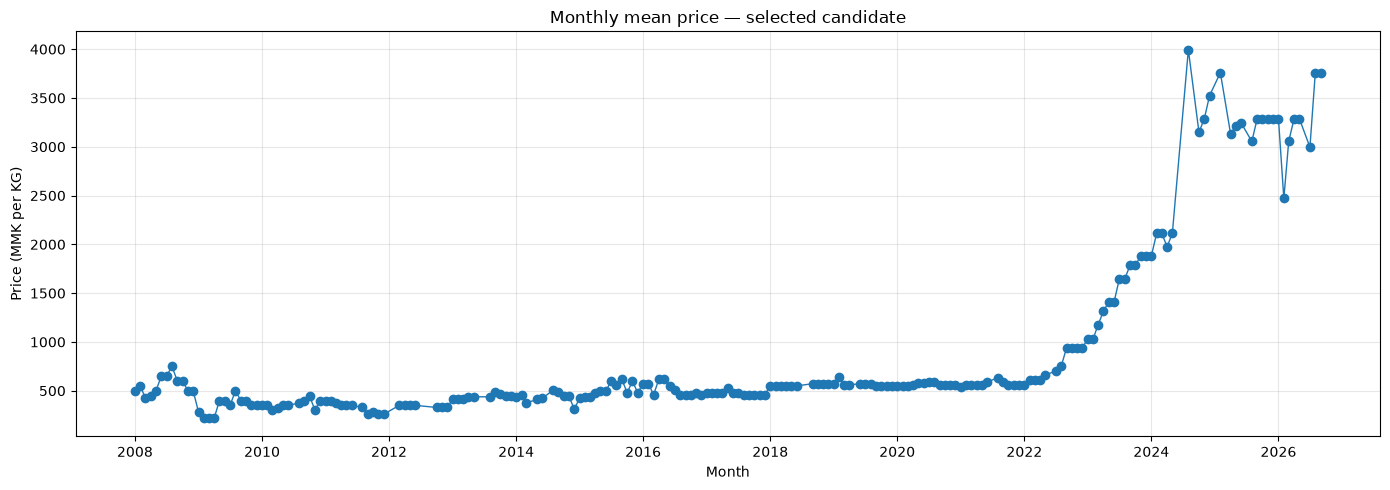

In [46]:
plt.figure(figsize=(14, 5))
plt.plot(
    selected_series["month"].dt.to_timestamp(),
    selected_series["monthly_mean_price"],
    marker="o",
    linewidth=1,
)

plt.title("Monthly mean price — selected candidate")
plt.xlabel("Month")
plt.ylabel(f"Price ({selected_candidate['currency']} per {selected_candidate['unit']})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 16. Export exploration outputs

These are intermediate outputs for further investigation, not yet the final modeling dataset.

- `series_coverage.csv`: coverage statistics for every series.
- `candidate_series.csv`: preliminary candidate shortlist.
- `candidate_monthly_prices.csv`: monthly aggregated observations for candidates.

Create the output directory if it does not exist.

In [40]:
OUTPUT_DIR = Path("../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

coverage.to_csv(OUTPUT_DIR / "series_coverage.csv", index=False)
candidates.to_csv(OUTPUT_DIR / "candidate_series.csv", index=False)
candidate_monthly_prices.to_csv(
    OUTPUT_DIR / "candidate_monthly_prices.csv",
    index=False,
)

print(f"Saved exploration outputs to: {OUTPUT_DIR.resolve()}")


Saved exploration outputs to: D:\machine learning projects\Myanmar-Food-Price-Forecasting\data\processed


## 17. Current findings and next steps

At the end of this notebook, record the actual results from your run:

- How many distinct commodity–market–measurement series were found?
- How many candidates remain under the latest-year and minimum-month filters?
- Which commodities and markets have the longest histories?
- Which candidate has a good balance of history and continuity?
- Are there multiple markets with overlapping histories for the same commodity?

### Next stage

1. Select a target commodity and market based on coverage and project relevance.
2. Inspect the target series for gaps, outliers, and unusual price changes.
3. Check whether other markets have overlapping histories for the same commodity.
4. Only then investigate cross-market or cross-commodity predictors.
5. Build a chronological train/validation/test split and a simple forecasting baseline.

**Do not treat the candidate shortlist as the final modeling dataset.** The final selection should follow the data-quality checks and the forecasting question.